# 🧪 Romanized Spelling Stability Benchmark (3 models, 100–200 questions per language)
### **Author:** Karan Sahi (Roll No.: 24CSU095) & Kanishk Singh(Roll No.:24CSU093)
**Paper:** *Does Spelling Choice Change the Answer? Stability of Small Open Language Models under Natural Romanized Spelling Variants in Hindi, Bengali and Tamil*

---
This notebook runs the **complete experimental pipeline**:
1. Loads parallel reading-comprehension questions from **Belebele** (Hindi, Bengali, Tamil) and draws a **random, seeded sample** of `NUM_QUESTIONS_PER_LANG` questions (default 200). The *same* questions are used in all three languages.
2. Builds the **8 input conditions once** (so every model sees identical text): $C_0$ Native, $C_1$ Modal Roman, $C_2$–$C_5$ rule-based spelling variants, $C_6$ keyboard typos, $C_7$ normalized back to native script.
3. Scores exact next-token logits for `A`, `B`, `C`, `D` on **three open models**: `Qwen2.5-3B-Instruct`, `Qwen3-4B`, `Gemma-3-4B-it`.
4. **Saves progress after every question**, so a Colab disconnect does not lose your work. Re-run the cell to resume.
5. Computes accuracy, answer flips ($C \to I$ vs $I \to C$) and pairwise consistency **per model**, and saves the tables, `experiment_results_all_models.csv` and Figure 1.

> **Runtime:** roughly 14,400 forward passes at 200 questions (3 languages × 200 × 8 conditions × 3 models). Expect about 1.5–3 hours on a free T4. Use 100 questions for a faster run.

### Step 1: Install Required Libraries

In [1]:
%pip install -q -U transformers accelerate "huggingface-hub>=0.25.0,<2.0"
%pip install -q indic-transliteration

### Step 2: Check Hardware (T4 GPU Verification)

In [2]:
import torch

print("PyTorch Version:", torch.__version__)
if torch.cuda.is_available():
    print("✅ GPU detected:", torch.cuda.get_device_name(0))
    print("VRAM Available:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), "GB")
else:
    print("⚠️ No GPU detected. Please go to Runtime -> Change runtime type -> select T4 GPU.")

PyTorch Version: 2.11.0+cu130
✅ GPU detected: Tesla T4
VRAM Available: 15.64 GB


### Step 3: Settings
Change these values here. Everything below reads from this cell.

In [3]:
import os

NUM_QUESTIONS_PER_LANG = 200   # 100 = faster run, 200 = full run (Belebele has 900 per language)
SAMPLE_SEED = 42               # fixes which questions are drawn, so the run is reproducible
TYPO_EDIT_RATE = 0.08          # C6 typo rate; compare with the measured variant change rate printed in Step 5

# Save progress to Google Drive so a disconnect does not erase it (recommended for the full run).
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = "/content/drive/MyDrive/romanized_spelling_results"
else:
    RESULTS_DIR = "/content/results"
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Results folder:", RESULTS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Results folder: /content/drive/MyDrive/romanized_spelling_results


### Step 4: Variant Generator & Transliteration Engine ($C_0$ to $C_7$)

In [4]:
# If indic-transliteration was not installed in Step 1, auto-install it now
try:
    from indic_transliteration import sanscript
    from indic_transliteration.sanscript import transliterate
except ModuleNotFoundError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "indic-transliteration"])
    from indic_transliteration import sanscript
    from indic_transliteration.sanscript import transliterate

import random
import difflib

SCRIPT_MAP = {"hi": sanscript.DEVANAGARI, "bn": sanscript.BENGALI, "ta": sanscript.TAMIL}

# Rule-based orthographic substitutions that mimic common informal Romanization habits.
# NOTE: these are hand-written rules, NOT spellings looked up from a human-written corpus.
SUBSTITUTION_RULES = [
    ("aa", "a"), ("ee", "i"), ("oo", "u"), ("th", "t"), ("dh", "d"),
    ("bh", "b"), ("kh", "k"), ("gh", "g"), ("ph", "f"), ("sh", "s"),
    ("v", "w"),  ("z", "j"),  ("a", "aa"), ("i", "ee"), ("u", "oo")
]

def romanize_modal(text: str, lang: str) -> str:
    """Condition C1: canonical Romanization using the ITRANS scheme, lower-cased."""
    script = SCRIPT_MAP.get(lang, sanscript.DEVANAGARI)
    rom = transliterate(text, script, sanscript.ITRANS)
    return rom.lower().replace("~", "").replace(".", "")

def generate_attested_variant(text_roman: str, seed) -> str:
    """Conditions C2-C5: rule-based respelling. `seed` may be any int or string."""
    rng = random.Random(seed)
    varied_words = []
    for w in text_roman.split():
        if len(w) <= 3 or not w.isalpha():
            varied_words.append(w)
            continue
        if rng.random() < 0.40:
            for src, target in rng.sample(SUBSTITUTION_RULES, len(SUBSTITUTION_RULES)):
                if src in w:
                    w = w.replace(src, target, 1)
                    break
        varied_words.append(w)
    return " ".join(varied_words)

def inject_keyboard_typos(text: str, edit_rate: float, seed) -> str:
    """Condition C6: random keyboard typos (substitute / insert / delete)."""
    rng = random.Random(seed)
    chars = list(text)
    alphabet = "abcdefghijklmnopqrstuvwxyz"
    for _ in range(int(len(chars) * edit_rate)):
        idx = rng.randint(0, len(chars) - 1)
        op = rng.choice(["sub", "insert", "del"])
        if op == "sub" and chars[idx].isalpha():
            chars[idx] = rng.choice(alphabet)
        elif op == "insert":
            chars.insert(idx, rng.choice(alphabet))
        elif op == "del" and len(chars) > 10:
            chars.pop(idx)
    return "".join(chars)

def normalize_to_native(text_roman: str, lang: str) -> str:
    """Condition C7: convert the modal Romanization back to native script."""
    script = SCRIPT_MAP.get(lang, sanscript.DEVANAGARI)
    try:
        return transliterate(text_roman, sanscript.ITRANS, script)
    except Exception:
        return text_roman

def char_change_rate(a: str, b: str) -> float:
    """Approximate share of characters that differ between two strings (difflib-based)."""
    return 1 - difflib.SequenceMatcher(None, a, b, autojunk=False).ratio()

print("Transliteration and variant generation functions defined successfully!")

Transliteration and variant generation functions defined successfully!


### Step 5: Load Belebele, Sample Questions, and Build All 8 Conditions (once)

In [5]:
from datasets import load_dataset

print("Downloading Belebele parallel dataset...")

def load_belebele(code):
    # Newer `datasets` versions expose each language as a config with a "test" split;
    # older versions expose each language as a split. Try the new layout first.
    try:
        return load_dataset("facebook/belebele", code, split="test")
    except Exception:
        return load_dataset("facebook/belebele", split=code)

dataset_splits = {
    "hi": load_belebele("hin_Deva"),
    "bn": load_belebele("ben_Beng"),
    "ta": load_belebele("tam_Taml"),
}

# The three language files list the SAME questions in a DIFFERENT order, so rows cannot be paired by position.
# Pair them by (passage link, question number) instead. The link is the English source URL, shared by all languages.
index_by_lang = {}
for lang, ds in dataset_splits.items():
    keys = list(zip(ds["link"], [int(q) for q in ds["question_number"]]))
    print(f"{lang}: {len(keys)} rows, {len(set(keys))} unique (link, question number) keys")
    assert len(set(keys)) == len(keys), f"{lang}: keys are not unique, cannot pair questions safely."
    index_by_lang[lang] = {k: n for n, k in enumerate(keys)}

common_keys = sorted(set(index_by_lang["hi"]) & set(index_by_lang["bn"]) & set(index_by_lang["ta"]))
print(f"Questions present in all three languages: {len(common_keys)}")
assert NUM_QUESTIONS_PER_LANG <= len(common_keys), f"Only {len(common_keys)} shared questions available."

# Random sample (not the first N): the first rows come from only a few passages.
SAMPLED_KEYS = random.Random(SAMPLE_SEED).sample(common_keys, NUM_QUESTIONS_PER_LANG)

# Safety check: a correctly paired question has its gold answer in the same position in every language.
agree = sum(
    len({int(dataset_splits[l][index_by_lang[l][k]]["correct_answer_num"]) for l in dataset_splits}) == 1
    for k in SAMPLED_KEYS
)
print(f"Gold-answer position agrees across languages for {agree} of {len(SAMPLED_KEYS)} paired questions.")
assert agree == len(SAMPLED_KEYS), "Pairing looks wrong. Send the lines printed above to your assistant."
print(f"Sampled {len(SAMPLED_KEYS)} questions per language (seed {SAMPLE_SEED}); languages are paired.")

LETTERS = ["A", "B", "C", "D"]
VARIANT_CONDS = ["c2_var1", "c3_var2", "c4_var3", "c5_var4"]
ALL_CONDS = ["c0_native", "c1_modal"] + VARIANT_CONDS + ["c6_typo", "c7_norm"]

prepared = {lang: [] for lang in dataset_splits}
for lang, ds in dataset_splits.items():
    for qid, key in enumerate(SAMPLED_KEYS):
        orig_idx = index_by_lang["hi"][key]   # one stable id per question, identical for all languages
        item = ds[index_by_lang[lang][key]]
        gold = LETTERS[int(item["correct_answer_num"]) - 1]
        p_nat, q_nat = item["flores_passage"], item["question"]
        o_nat = [item["mc_answer1"], item["mc_answer2"], item["mc_answer3"], item["mc_answer4"]]

        p_mod, q_mod = romanize_modal(p_nat, lang), romanize_modal(q_nat, lang)
        o_mod = [romanize_modal(o, lang) for o in o_nat]
        modal = (p_mod, q_mod, o_mod)

        inputs = {"c0_native": (p_nat, q_nat, o_nat), "c1_modal": modal}
        n_identical, cers = 0, []
        for k, cond in enumerate(VARIANT_CONDS, start=1):
            tag = f"{lang}|{orig_idx}|{k}"
            p_v = generate_attested_variant(p_mod, tag + "|p")
            q_v = generate_attested_variant(q_mod, tag + "|q")
            o_v = [generate_attested_variant(o, tag + f"|o{j}") for j, o in enumerate(o_mod)]
            inputs[cond] = (p_v, q_v, o_v)
            n_identical += int((p_v, q_v, o_v) == modal)
            cers.append(char_change_rate(p_mod, p_v))

        tag = f"{lang}|{orig_idx}|typo"
        p_t = inject_keyboard_typos(p_mod, TYPO_EDIT_RATE, tag + "|p")
        q_t = inject_keyboard_typos(q_mod, TYPO_EDIT_RATE, tag + "|q")
        o_t = [inject_keyboard_typos(o, TYPO_EDIT_RATE, tag + f"|o{j}") for j, o in enumerate(o_mod)]
        inputs["c6_typo"] = (p_t, q_t, o_t)

        inputs["c7_norm"] = (normalize_to_native(p_mod, lang), normalize_to_native(q_mod, lang),
                             [normalize_to_native(o, lang) for o in o_mod])

        prepared[lang].append({
            "lang": lang, "qid": qid, "orig_idx": orig_idx, "gold": gold, "inputs": inputs,
            "n_var_identical": n_identical,
            "var_change_rate": sum(cers) / len(cers),
            "typo_change_rate": char_change_rate(p_mod, p_t),
        })

print("\nInput quality checks (read these before running the models):")
for lang, recs in prepared.items():
    n = len(recs)
    print(f"  {lang.upper()}: variants change {100*sum(r['var_change_rate'] for r in recs)/n:.1f}% of passage characters on average; "
          f"typos change {100*sum(r['typo_change_rate'] for r in recs)/n:.1f}%; "
          f"{100*sum(r['n_var_identical'] for r in recs)/(4*n):.1f}% of variants are identical to C1.")
    native_back = sum(r["inputs"]["c7_norm"][0] == r["inputs"]["c0_native"][0] for r in recs)
    print(f"      C7 (round trip) reproduces the original native passage exactly for {100*native_back/n:.1f}% of questions.")
    leftover = sum(sum(ord(ch) > 127 for ch in r["inputs"]["c1_modal"][0]) for r in recs) / max(1, sum(len(r["inputs"]["c1_modal"][0]) for r in recs))
    print(f"      Non-Latin characters left inside the 'Romanized' C1 passages: {100*leftover:.2f}% of characters.")

hi: 900 rows, 900 unique (link, question number) keys
bn: 900 rows, 900 unique (link, question number) keys
ta: 900 rows, 900 unique (link, question number) keys
Questions present in all three languages: 900
Gold-answer position agrees across languages for 200 of 200 paired questions.
Sampled 200 questions per language (seed 42); languages are paired.

Input quality checks (read these before running the models):
  HI: variants change 3.2% of passage characters on average; typos change 4.6%; 0.0% of variants are identical to C1.
      C7 (round trip) reproduces the original native passage exactly for 0.0% of questions.
      Non-Latin characters left inside the 'Romanized' C1 passages: 0.26% of characters.
  BN: variants change 2.9% of passage characters on average; typos change 4.7%; 0.0% of variants are identical to C1.
      C7 (round trip) reproduces the original native passage exactly for 0.0% of questions.
      Non-Latin characters left inside the 'Romanized' C1 passages: 0.85% o

### Step 6: Model Configuration & Loading
Three open models that fit on a free T4 GPU:

| Key | Model | Notes |
|---|---|---|
| `qwen2.5-3b` | `Qwen/Qwen2.5-3B-Instruct` | open |
| `qwen3-4b` | `Qwen/Qwen3-4B` | open, thinking mode switched off |
| `gemma3-4b` | `google/gemma-3-4b-it` | **gated**: accept the licence at huggingface.co/google/gemma-3-4b-it, then log in below |

Only one model is in GPU memory at a time.

In [6]:
from huggingface_hub import login
# Needed for Gemma. Paste a Hugging Face token (Settings -> Access Tokens) when prompted,
# or add it as a Colab secret named HF_TOKEN. Press Enter / ignore if you will skip Gemma.
try:
    from google.colab import userdata
    login(token=userdata.get("HF_TOKEN"))
except Exception:
    login()

In [7]:
import gc, math
from transformers import AutoModelForCausalLM, AutoTokenizer

MODELS = {
    "qwen2.5-3b": {"id": "Qwen/Qwen2.5-3B-Instruct", "dtype": torch.float16, "chat_kwargs": {}},
    "qwen3-4b":   {"id": "Qwen/Qwen3-4B",            "dtype": torch.float16, "chat_kwargs": {"enable_thinking": False}},
    "gemma3-4b":  {"id": "google/gemma-3-4b-it",     "dtype": torch.bfloat16, "chat_kwargs": {}},
}

M = {}  # the model currently in memory

def load_model(key):
    cfg = MODELS[key]
    print(f"\nLoading {cfg['id']} ...")
    tok = AutoTokenizer.from_pretrained(cfg["id"])
    try:
        model = AutoModelForCausalLM.from_pretrained(cfg["id"], torch_dtype=cfg["dtype"], device_map="auto")
    except Exception as e:
        if "gemma" not in key:
            raise
        print("AutoModelForCausalLM failed for Gemma, trying Gemma3ForConditionalGeneration:", repr(e)[:200])
        from transformers import Gemma3ForConditionalGeneration
        model = Gemma3ForConditionalGeneration.from_pretrained(cfg["id"], torch_dtype=cfg["dtype"], device_map="auto")
    model.eval()
    ids = {l: tok.encode(l, add_special_tokens=False)[-1] for l in LETTERS}
    print("Answer-letter token ids:", ids, "->", [tok.decode([i]) for i in ids.values()])
    M.update({"key": key, "tok": tok, "model": model, "ids": ids, "chat_kwargs": cfg["chat_kwargs"]})

def unload_model():
    M.clear(); gc.collect(); torch.cuda.empty_cache()

### Step 7: Logit Scoring Function (Deterministic Evaluation)

In [8]:
INSTRUCTION = "Read the passage and answer the multiple-choice question. Reply with only the letter of the correct option (A, B, C or D)."

def score_mcq(passage: str, question: str, options: list) -> tuple:
    """Return (chosen letter, margin between the top two letters) using next-token logits."""
    opts = "\n".join(f"{l}) {o}" for l, o in zip(LETTERS, options))
    prompt = f"{INSTRUCTION}\n\nPassage:\n{passage}\n\nQuestion:\n{question}\n\nOptions:\n{opts}"
    chat = M["tok"].apply_chat_template([{"role": "user", "content": prompt}], tokenize=False,
                                        add_generation_prompt=True, **M["chat_kwargs"])
    # The chat template already contains any special tokens (e.g. Gemma's <bos>), so do not add them twice.
    inputs = M["tok"](chat, return_tensors="pt", add_special_tokens=False).to(M["model"].device)
    with torch.inference_mode():
        try:
            out = M["model"](**inputs, logits_to_keep=1)
        except TypeError:
            out = M["model"](**inputs)
        last = out.logits[0, -1, :].float()
    vals = {l: float(last[M["ids"][l]]) for l in LETTERS}
    if not all(math.isfinite(v) for v in vals.values()):
        raise RuntimeError(f"Non-finite logits from {M['key']} (try float16 <-> bfloat16 in MODELS).")
    ranked = sorted(vals.values(), reverse=True)
    return max(vals, key=vals.get), ranked[0] - ranked[1]

### Step 8: Run the Benchmark (resumable)
Each answer is written to a `.jsonl` file in your results folder immediately. If Colab disconnects, reconnect, run Steps 1–7 again, then re-run this cell. It skips everything already finished.

In [9]:
import json
import pandas as pd
from tqdm.auto import tqdm

def result_path(key, lang):
    return os.path.join(RESULTS_DIR, f"{key}_{lang}_n{NUM_QUESTIONS_PER_LANG}_s{SAMPLE_SEED}.jsonl")

def done_ids(key, lang):
    path = result_path(key, lang)
    if not os.path.exists(path):
        return set()
    with open(path) as fh:
        return {json.loads(line)["qid"] for line in fh if line.strip()}

for key in MODELS:
    pending = {lang: [r for r in prepared[lang] if r["qid"] not in done_ids(key, lang)] for lang in prepared}
    if not any(pending.values()):
        print(f"✅ {key}: already complete, skipping.")
        continue
    load_model(key)
    for lang in prepared:
        if not pending[lang]:
            continue
        print(f"\n🚀 {key} | {lang.upper()} | {len(pending[lang])} questions left")
        with open(result_path(key, lang), "a") as fh:
            for rec in tqdm(pending[lang]):
                row = {"model": key, "lang": lang, "qid": rec["qid"], "orig_idx": rec["orig_idx"], "gold": rec["gold"],
                       "n_var_identical": rec["n_var_identical"], "var_change_rate": rec["var_change_rate"],
                       "typo_change_rate": rec["typo_change_rate"]}
                for cond, (p, q, o) in rec["inputs"].items():
                    ans, margin = score_mcq(p, q, o)
                    row[cond] = ans
                    if cond == "c1_modal":
                        row["modal_margin"] = margin
                fh.write(json.dumps(row) + "\n")
                fh.flush()
    unload_model()

frames = []
for key in MODELS:
    for lang in prepared:
        path = result_path(key, lang)
        if os.path.exists(path):
            frames.append(pd.read_json(path, lines=True))
df = pd.concat(frames, ignore_index=True)
df.to_csv("experiment_results_all_models.csv", index=False)
print(df.groupby(["model", "lang"]).size().unstack())
print("✅ Raw data saved to experiment_results_all_models.csv")

✅ qwen2.5-3b: already complete, skipping.
✅ qwen3-4b: already complete, skipping.

Loading google/gemma-3-4b-it ...


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

... (10 outputs left out)

  0%|          | 0/200 [00:00<?, ?it/s]


🚀 gemma3-4b | TA | 200 questions left


  0%|          | 0/200 [00:00<?, ?it/s]

lang         bn   hi   ta
model                    
gemma3-4b   200  200  200
qwen2.5-3b  200  200  200
qwen3-4b    200  200  200
✅ Raw data saved to experiment_results_all_models.csv


### Step 9: Compute Final Statistics (Table III & Table IV, per model)

In [10]:
def accuracy_table(sub_all):
    rows = []
    for lang in ["hi", "bn", "ta"]:
        sub = sub_all[sub_all["lang"] == lang]
        acc = lambda col: (sub[col] == sub["gold"]).mean() * 100
        rows.append({"Language": lang.upper(), "N": len(sub),
                     "C0 (Native)": acc("c0_native"), "C1 (Modal)": acc("c1_modal"),
                     "C2-C5 (Variants)": sum(acc(c) for c in VARIANT_CONDS) / 4.0,
                     "C6 (Typos)": acc("c6_typo"), "C7 (Norm)": acc("c7_norm")})
    return pd.DataFrame(rows)

def flip_table(sub_all):
    rows = []
    for lang in ["hi", "bn", "ta"]:
        sub = sub_all[sub_all["lang"] == lang]
        n = len(sub)
        c_to_i = i_to_c = any_change = all_agree = pair_match = 0
        cols = ["c1_modal"] + VARIANT_CONDS
        for _, r in sub.iterrows():
            c1, gold, vs = r["c1_modal"], r["gold"], [r[c] for c in VARIANT_CONDS]
            if all(v == c1 for v in vs):
                all_agree += 1
            if any(v != c1 for v in vs):
                any_change += 1
                if c1 == gold:
                    c_to_i += 1
                elif any(v == gold for v in vs):
                    i_to_c += 1
            vals = [r[c] for c in cols]
            pair_match += sum(vals[a] == vals[b] for a in range(5) for b in range(a + 1, 5))
        rows.append({"Language": lang.upper(), "N": n,
                     "Correct -> Incorrect": c_to_i / n * 100, "Incorrect -> Correct": i_to_c / n * 100,
                     "Total Flips": any_change / n * 100, "All-5 Agree": all_agree / n * 100,
                     "Pairwise Agreement": pair_match / (n * 10) * 100,
                     "Typo Flips (C6)": (sub["c6_typo"] != sub["c1_modal"]).mean() * 100,
                     "Variants identical to C1": sub["n_var_identical"].sum() / (4 * n) * 100})
    return pd.DataFrame(rows)

acc_tables, flip_tables = {}, {}
for key in MODELS:
    sub_all = df[df["model"] == key]
    if sub_all.empty:
        continue
    acc_tables[key], flip_tables[key] = accuracy_table(sub_all), flip_table(sub_all)
    print("=" * 78); print(f"MODEL: {MODELS[key]['id']}"); print("=" * 78)
    print("TABLE III: ACCURACY (%)"); print(acc_tables[key].round(1).to_string(index=False))
    print("\nTABLE IV: FLIPS & STABILITY (%) relative to C1"); print(flip_tables[key].round(1).to_string(index=False)); print()

pd.concat({k: v for k, v in acc_tables.items()}).to_csv("table3_accuracy.csv")
pd.concat({k: v for k, v in flip_tables.items()}).to_csv("table4_flips.csv")
print("Saved table3_accuracy.csv and table4_flips.csv")

MODEL: Qwen/Qwen2.5-3B-Instruct
TABLE III: ACCURACY (%)
Language   N  C0 (Native)  C1 (Modal)  C2-C5 (Variants)  C6 (Typos)  C7 (Norm)
      HI 200         51.5        31.0              34.0        30.5       41.0
      BN 200         56.0        36.0              37.0        37.0       38.5
      TA 200         38.5        29.0              27.8        25.0       33.0

TABLE IV: FLIPS & STABILITY (%) relative to C1
Language   N  Correct -> Incorrect  Incorrect -> Correct  Total Flips  All-5 Agree  Pairwise Agreement  Typo Flips (C6)  Variants identical to C1
      HI 200                  17.5                  24.0         64.5         35.5                63.6             41.5                       0.0
      BN 200                  18.0                  24.0         58.0         42.0                67.5             38.5                       0.0
      TA 200                  15.0                  15.5         49.0         51.0                73.0             41.0                       

### Step 10: Render & Save Figure 1 (one panel per model)

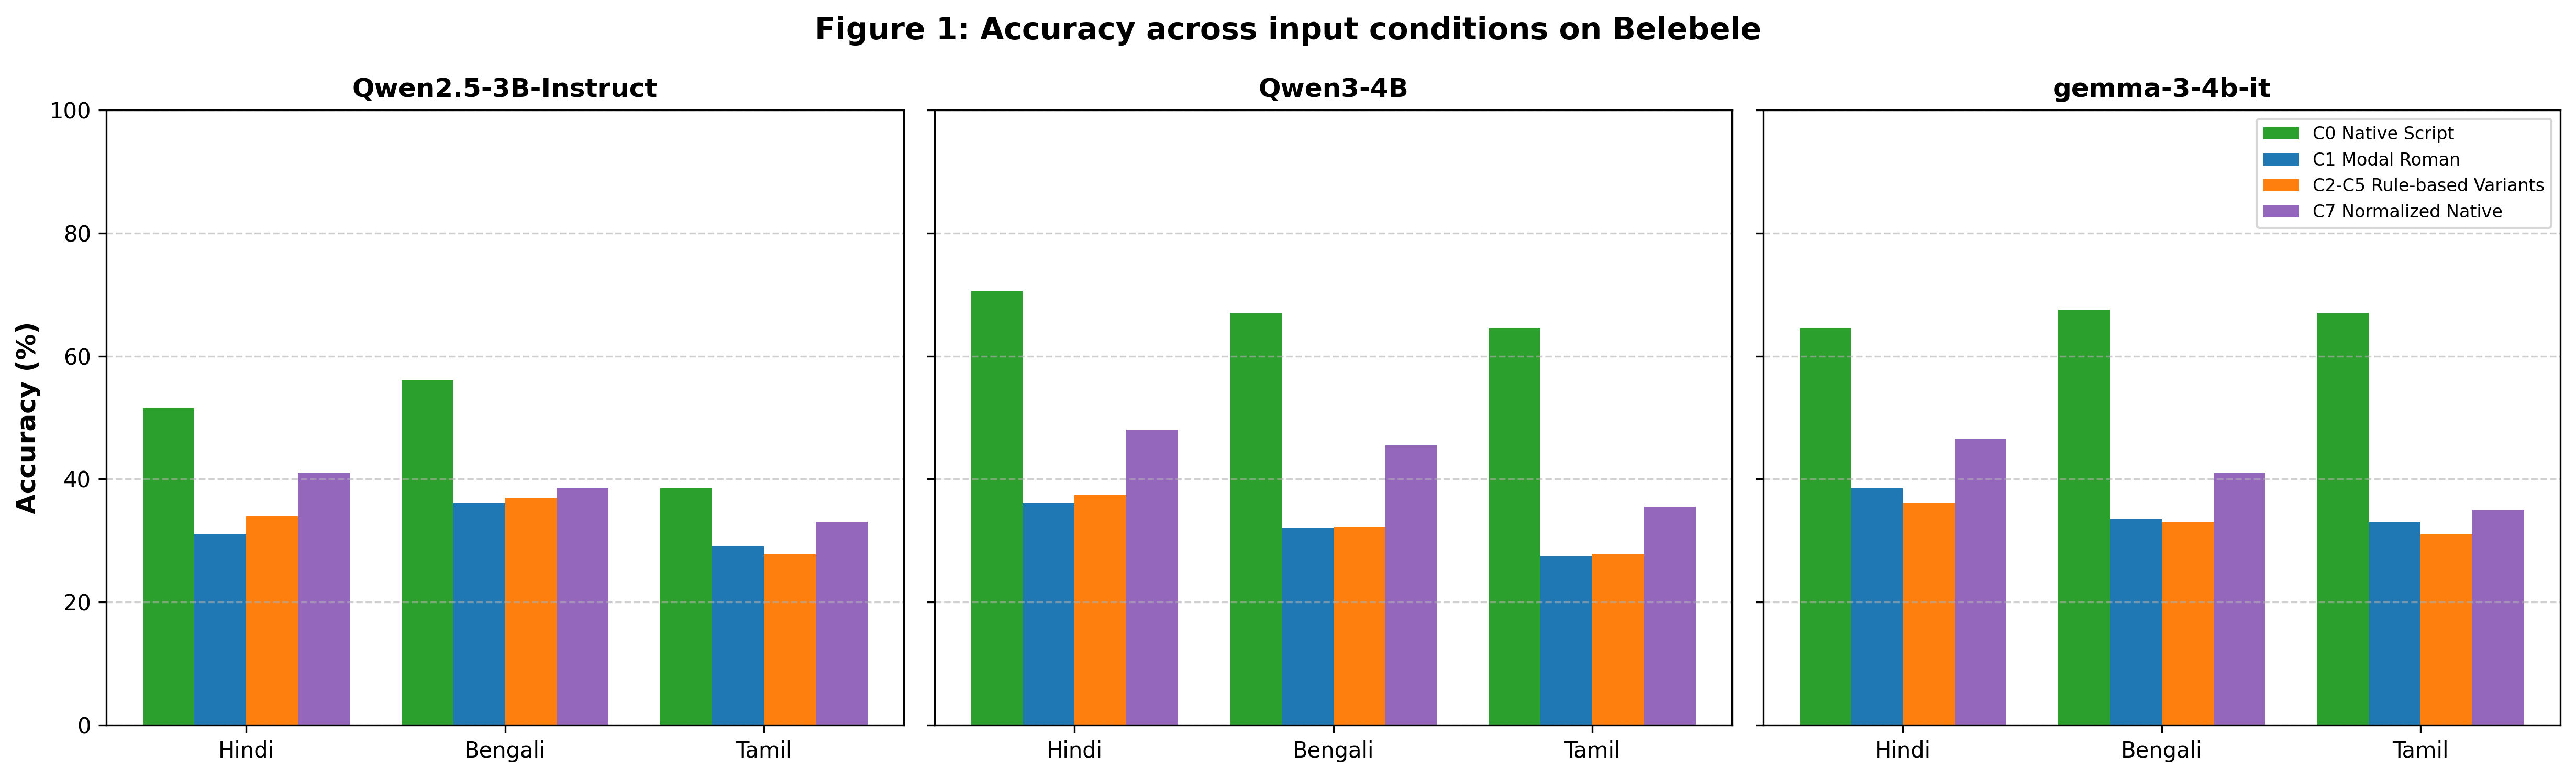

✅ Figure 1 saved to figure1_stability_chart.png


In [11]:
import matplotlib.pyplot as plt
import numpy as np

keys = list(acc_tables)
langs = ["Hindi", "Bengali", "Tamil"]
x = np.arange(len(langs)); width = 0.20
series = [("C0 Native Script", "C0 (Native)", "#2ca02c"), ("C1 Modal Roman", "C1 (Modal)", "#1f77b4"),
          ("C2-C5 Rule-based Variants", "C2-C5 (Variants)", "#ff7f0e"), ("C7 Normalized Native", "C7 (Norm)", "#9467bd")]

fig, axes = plt.subplots(1, len(keys), figsize=(5.5 * len(keys), 5), dpi=300, sharey=True, squeeze=False)
for ax, key in zip(axes[0], keys):
    for s, (label, col, color) in enumerate(series):
        ax.bar(x + (s - 1.5) * width, acc_tables[key][col].values, width, label=label, color=color)
    ax.set_title(MODELS[key]["id"].split("/")[-1], fontsize=12, fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(langs); ax.set_ylim(0, 100)
    ax.grid(axis="y", linestyle="--", alpha=0.6)
axes[0][0].set_ylabel("Accuracy (%)", fontsize=12, fontweight="bold")
axes[0][-1].legend(frameon=True, fontsize=8)
fig.suptitle("Figure 1: Accuracy across input conditions on Belebele", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figure1_stability_chart.png", dpi=300)
plt.show()
print("✅ Figure 1 saved to figure1_stability_chart.png")